In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    StandardScaler
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV



project_folder = Path.cwd()

data_folder = project_folder / "data" / "raw"

results = pd.read_csv(data_folder / "results.csv")
races = pd.read_csv(data_folder / "races.csv")
drivers = pd.read_csv(data_folder / "drivers.csv")
constructors = pd.read_csv(data_folder / "constructors.csv")

In [3]:
# Merge the dataframes to create a single dataframe with all relevant information
f1v1 = results.merge(
    races,
    on="raceId",
    how="left",
    suffixes=("", "_race")
)

f1v1 = f1v1.merge(
    drivers,
    on="driverId",
    how="left",
    suffixes=("", "_driver")
)

f1v1 = f1v1.merge(
    constructors,
    on="constructorId",
    how="left",
    suffixes=("", "_constructor")
)

# Keep only driver-race-team groups with exactly two teammates
team_size = f1v1.groupby(
    ["raceId", "constructorId"]
)["driverId"].transform("size")

f1v1 = f1v1[team_size == 2].copy()

# Create a small teammate table
teammate_data = f1v1[
    ["raceId", "constructorId", "driverId", "grid", "positionOrder"]
].rename(
    columns={
        "driverId": "teammate_driverId",
        "grid": "teammate_grid",
        "positionOrder": "teammate_positionOrder"
    }
)

# Match each driver with their teammate in the same race and constructor
f1v1 = f1v1.merge(
    teammate_data,
    on=["raceId", "constructorId"],
    how="left"
)

# Remove the row where a driver was matched with themselves
f1v1 = f1v1[
    f1v1["driverId"] != f1v1["teammate_driverId"]
].copy()

# Target: Y = finished ahead of teammate, N = finished behind
f1v1["beat_teammate"] = "N"

f1v1.loc[
    f1v1["positionOrder"] < f1v1["teammate_positionOrder"],
    "beat_teammate"
] = "Y"

# Feature: positive = starts ahead, negative = starts behind
f1v1["grid_gap_to_teammate"] = (
    f1v1["teammate_grid"] - f1v1["grid"]
)

# Remove temporary teammate columns
f1v1 = f1v1.drop(
    columns=[
        "teammate_driverId",
        "teammate_grid",
        "teammate_positionOrder"
    ]
)
# Create driver age at the date of each race
from src.features import add_driver_age

f1v1 = add_driver_age(f1v1)

# Sort races in chronological order
f1v1 = f1v1.sort_values(
    ["year", "round", "raceId", "driverId"]
).copy()

# 1. Driver points earned before the current race, within the same season
f1v1["prior_driver_points"] = (
    f1v1.groupby(["year", "driverId"])["points"]
    .transform(lambda values: values.shift().cumsum())
    .fillna(0)
)

# 2. Difference between the driver's prior points and teammate's prior points
f1v1["teammate_prior_driver_points"] = (
    f1v1.groupby(["raceId", "constructorId"])["prior_driver_points"]
    .transform("sum")
    - f1v1["prior_driver_points"]
)

f1v1["prior_driver_points_gap_to_teammate"] = (
    f1v1["prior_driver_points"]
    - f1v1["teammate_prior_driver_points"]
)

# Temporary column: 1 when the driver beat the teammate, otherwise 0
f1v1["teammate_win"] = (
    f1v1["beat_teammate"] == "Y"
).astype(int)

# 3. Number of teammate wins before the current race
f1v1["prior_teammate_wins"] = (
    f1v1.groupby("driverId")["teammate_win"]
    .transform(lambda values: values.shift().cumsum())
    .fillna(0)
)

# Number of previous races against a teammate
f1v1["prior_teammate_races"] = (
    f1v1.groupby("driverId").cumcount()
)

# 4. Historical rate of beating a teammate
f1v1["prior_teammate_win_rate"] = (
    f1v1["prior_teammate_wins"]
    / f1v1["prior_teammate_races"]
).fillna(0.5)

# Remove temporary helper columns
f1v1 = f1v1.drop(
    columns=[
        "teammate_prior_driver_points",
        "teammate_win"
    ]
)
# Create driver career history from all official race results

driver_race_history = results[
    [
        "raceId",
        "driverId"
    ]
].drop_duplicates()

driver_race_history = driver_race_history.merge(
    races[
        [
            "raceId",
            "year",
            "round"
        ]
    ],
    on="raceId",
    how="left"
)

# Put each driver's races in chronological order
driver_race_history = driver_race_history.sort_values(
    [
        "year",
        "round",
        "raceId",
        "driverId"
    ]
).copy()

# Number of F1 races completed before the current race
driver_race_history["prior_f1_races"] = (
    driver_race_history.groupby("driverId").cumcount()
)

# One row per driver per season
driver_seasons = driver_race_history[
    [
        "driverId",
        "year"
    ]
].drop_duplicates()

driver_seasons = driver_seasons.sort_values(
    [
        "driverId",
        "year"
    ]
).copy()

# Number of F1 seasons before the current season
driver_seasons["prior_f1_seasons"] = (
    driver_seasons.groupby("driverId").cumcount()
)

# Add season experience to every driver-race row
driver_race_history = driver_race_history.merge(
    driver_seasons,
    on=[
        "driverId",
        "year"
    ],
    how="left"
)

# Remove old versions if the cell is run again
f1v1 = f1v1.drop(
    columns=[
        "prior_f1_seasons",
        "prior_f1_races"
    ],
    errors="ignore"
)

# Add the two career-experience features to the main dataframe
f1v1 = f1v1.merge(
    driver_race_history[
        [
            "raceId",
            "driverId",
            "prior_f1_seasons",
            "prior_f1_races"
        ]
    ],
    on=[
        "raceId",
        "driverId"
    ],
    how="left",
    validate="many_to_one"
)

print(
    f1v1[
        [
            "prior_f1_seasons",
            "prior_f1_races"
        ]
    ].isna().sum()
)
f1v1.head()

prior_f1_seasons    0
prior_f1_races      0
dtype: int64


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,beat_teammate,grid_gap_to_teammate,driver_age,prior_driver_points,prior_driver_points_gap_to_teammate,prior_teammate_wins,prior_teammate_races,prior_teammate_win_rate,prior_f1_seasons,prior_f1_races
0,20037,833,776,126,23,19,\N,N,13,0.0,...,Y,-2,37,0.0,0.0,0.0,0,0.5,0,0
1,20040,833,785,126,24,17,\N,R,16,0.0,...,N,2,29,0.0,0.0,0.0,0,0.5,0,0
2,20061,834,427,141,12,13,\N,R,16,0.0,...,N,-2,32,0.0,0.0,0.0,0,0.5,0,0
3,20051,834,619,151,26,16,6,6,6,0.0,...,Y,-2,36,0.0,0.0,0.0,0,0.5,0,1
4,20059,834,626,141,10,11,\N,R,14,0.0,...,Y,2,33,0.0,0.0,0.0,0,0.5,0,0


Train Test Split

In [4]:
# Selected features
numeric_features = [
    "grid",
    "grid_gap_to_teammate",
    "year",
    "round",
    "driver_age",
    "prior_driver_points",
    "prior_driver_points_gap_to_teammate",
    "prior_teammate_wins",
    "prior_teammate_win_rate",
    "prior_f1_seasons",
    "prior_f1_races"
]

categorical_features = [
    "driverId"
]

selected_features = numeric_features + categorical_features

Features = f1v1[selected_features].copy()

Target = f1v1["beat_teammate"]

X_train, X_test, y_train, y_test = train_test_split(
    Features,
    Target,
    test_size=0.2,
    random_state=28,
    stratify=Target
)

One Hot Encoder

In [5]:

# Create the encoder
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

# Learn categories from training data only
encoder.fit(X_train[categorical_features])

# Transform categorical columns
X_train_categorical = pd.DataFrame(
    encoder.transform(X_train[categorical_features]),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)

X_test_categorical = pd.DataFrame(
    encoder.transform(X_test[categorical_features]),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)

# Combine numeric features with encoded categorical features
X_train_encoded = pd.concat(
    [
        X_train[numeric_features],
        X_train_categorical
    ],
    axis=1
)

X_test_encoded = pd.concat(
    [
        X_test[numeric_features],
        X_test_categorical
    ],
    axis=1
)

print("Training shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)

Training shape: (16680, 496)
Test shape: (4170, 496)


KNN

In [6]:
# KNN baseline: no normalization

knn_base = KNeighborsClassifier()

knn_base.fit(X_train_encoded, y_train)

base_score = knn_base.score(X_test_encoded, y_test)

pred_base = knn_base.predict(X_test_encoded)

comparison_base = pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "predicted": pred_base
    }
)

print("Baseline accuracy:", base_score)

comparison_base.head(10)

Baseline accuracy: 0.5673860911270984


,actual,predicted
0,N,Y
1,N,Y
2,N,N
3,Y,Y
4,N,Y
5,N,N
6,Y,N
7,N,N
8,N,N
9,N,Y


KNN Standardscaler

In [7]:
# KNN with StandardScaler

standard_scaler = StandardScaler()

X_train_numeric_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)

X_test_numeric_standard = pd.DataFrame(
    standard_scaler.transform(X_test[numeric_features]),
    columns=numeric_features,
    index=X_test.index
)

X_train_standard = pd.concat(
    [X_train_numeric_standard, X_train_categorical],
    axis=1
)

X_test_standard = pd.concat(
    [X_test_numeric_standard, X_test_categorical],
    axis=1
)

knn_standard = KNeighborsClassifier()

knn_standard.fit(X_train_standard, y_train)

standard_score = knn_standard.score(X_test_standard, y_test)

print("StandardScaler accuracy:", standard_score)

StandardScaler accuracy: 0.5839328537170264


MinMax Scaler Accuracy

In [8]:
# KNN with MinMaxScaler

minmax_scaler = MinMaxScaler()

X_train_numeric_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)

X_test_numeric_minmax = pd.DataFrame(
    minmax_scaler.transform(X_test[numeric_features]),
    columns=numeric_features,
    index=X_test.index
)

X_train_minmax = pd.concat(
    [X_train_numeric_minmax, X_train_categorical],
    axis=1
)

X_test_minmax = pd.concat(
    [X_test_numeric_minmax, X_test_categorical],
    axis=1
)

knn_minmax = KNeighborsClassifier()

knn_minmax.fit(X_train_minmax, y_train)

minmax_score = knn_minmax.score(X_test_minmax, y_test)

print("MinMaxScaler accuracy:", minmax_score)

MinMaxScaler accuracy: 0.5671462829736211


KNN CONFUSION MATRIX

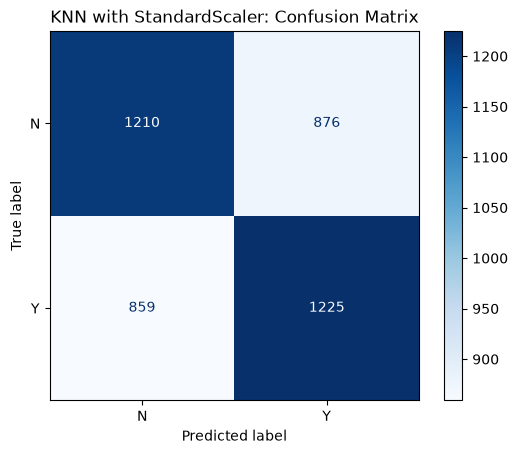

In [9]:
# Predictions from the best model
pred_standard = knn_standard.predict(X_test_standard)

# Create the confusion matrix
cm = confusion_matrix(
    y_test,
    pred_standard,
    labels=["N", "Y"]
)

# Display it
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["N", "Y"]
)

display.plot(cmap="Blues")

plt.title("KNN with StandardScaler: Confusion Matrix")

plt.show()

FEATURE CORRELATION MATRIX

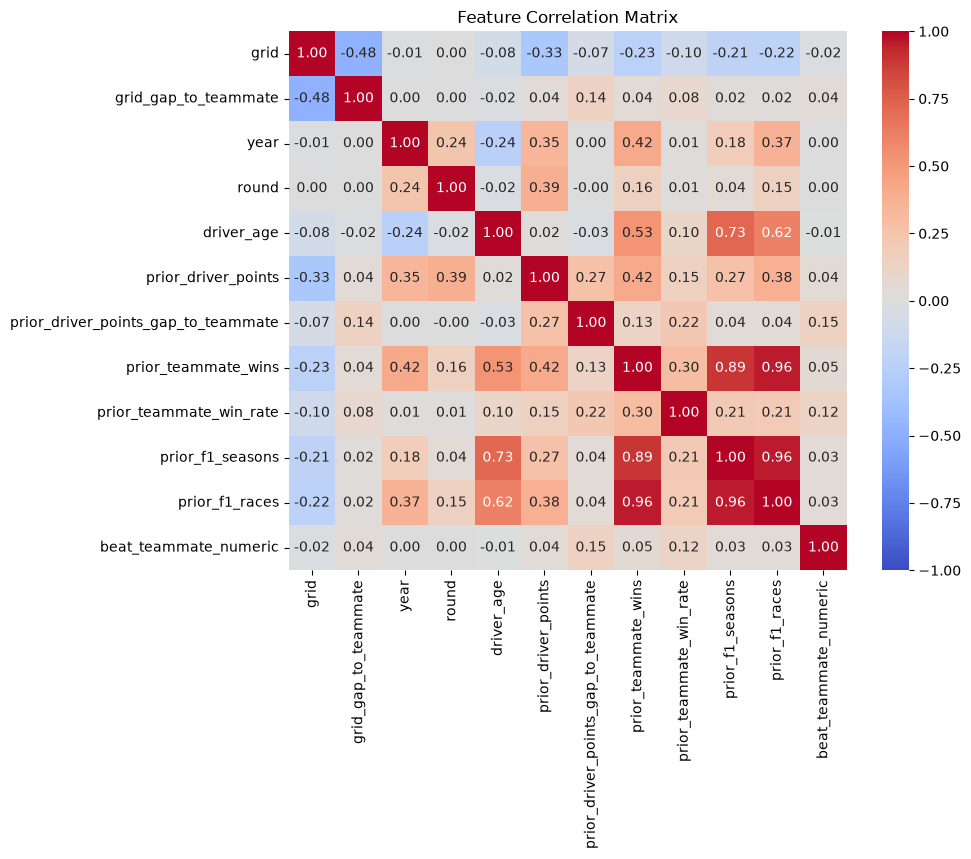

In [10]:


# Create a numeric version of the target only for correlation analysis
selection_data = f1v1[numeric_features + ["beat_teammate"]].copy()

selection_data["beat_teammate_numeric"] = selection_data["beat_teammate"].map(
    {"N": 0, "Y": 1}
)

# Keep only numerical columns for the correlation matrix
correlation_data = selection_data[
    numeric_features + ["beat_teammate_numeric"]
]

# Calculate correlations
correlation_matrix = correlation_data.corr()

# Plot the correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

In [11]:
# Decision Tree input: raw numerical features + encoded driverId
X_train_tree = X_train_encoded.copy()
X_test_tree = X_test_encoded.copy()

Decision Tree Classifier

In [12]:
# Default Decision Tree for the first comparison
decision_tree = DecisionTreeClassifier(
    random_state=28
)


Decision Tree accuracy: 0.5597122302158274

Decision Tree classification report:
              precision    recall  f1-score   support

           N       0.56      0.55      0.55      2086
           Y       0.56      0.57      0.57      2084

    accuracy                           0.56      4170
   macro avg       0.56      0.56      0.56      4170
weighted avg       0.56      0.56      0.56      4170



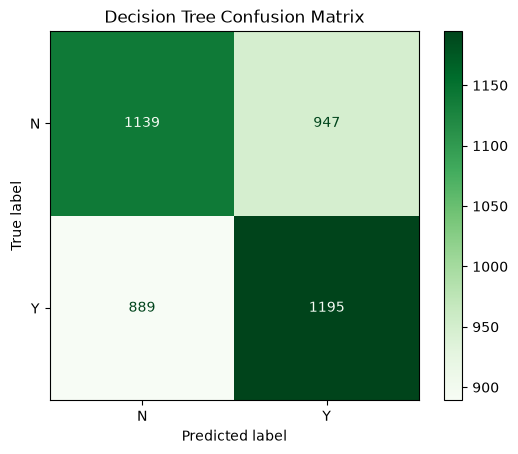

In [13]:
decision_tree.fit(X_train_tree, y_train)

tree_predictions = decision_tree.predict(X_test_tree)

tree_accuracy = accuracy_score(y_test, tree_predictions)

print("Decision Tree accuracy:", tree_accuracy)

print("\nDecision Tree classification report:")
print(classification_report(y_test, tree_predictions, labels=["N", "Y"]))

tree_matrix = confusion_matrix(
    y_test,
    tree_predictions,
    labels=["N", "Y"]
)

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=tree_matrix,
    display_labels=["N", "Y"]
)

confusion_display.plot(cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [14]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, None]

results = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=28
    )

    tree.fit(X_train_tree, y_train)

    train_accuracy = tree.score(X_train_tree, y_train)
    test_accuracy = tree.score(X_test_tree, y_test)

    results.append(
        {
            "max_depth": depth,
            "train_accuracy": train_accuracy,
            "test_accuracy": test_accuracy
        }
    )

depth_results = pd.DataFrame(results)

depth_results

,max_depth,train_accuracy,test_accuracy
0,1.0,0.586811,0.563070
1,2.0,0.622662,0.599760
2,3.0,0.623141,0.601439
3,4.0,0.623501,0.601199
4,5.0,0.625779,0.596882
5,6.0,0.631954,0.599281
6,8.0,0.649820,0.598082
7,10.0,0.674341,0.595683
8,15.0,0.761631,0.573861
9,NaN,1.000000,0.559712


Final Decision Tree accuracy: 0.6014388489208633

Final Decision Tree classification report:
              precision    recall  f1-score   support

           N       0.60      0.62      0.61      2086
           Y       0.61      0.58      0.59      2084

    accuracy                           0.60      4170
   macro avg       0.60      0.60      0.60      4170
weighted avg       0.60      0.60      0.60      4170



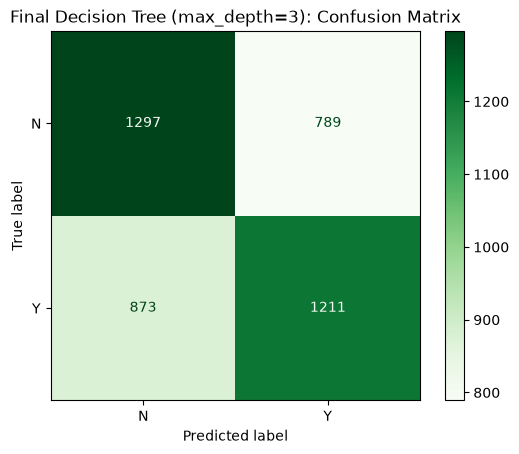

In [15]:
# Final Decision Tree: chosen after the max_depth comparison

final_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=28
)

final_tree.fit(X_train_tree, y_train)

final_tree_predictions = final_tree.predict(X_test_tree)

# Accuracy
final_tree_accuracy = accuracy_score(
    y_test,
    final_tree_predictions
)

print("Final Decision Tree accuracy:", final_tree_accuracy)

# Precision, recall and F1-score
print("\nFinal Decision Tree classification report:")
print(
    classification_report(
        y_test,
        final_tree_predictions,
        labels=["N", "Y"]
    )
)

# Confusion matrix
final_tree_matrix = confusion_matrix(
    y_test,
    final_tree_predictions,
    labels=["N", "Y"]
)

final_tree_display = ConfusionMatrixDisplay(
    confusion_matrix=final_tree_matrix,
    display_labels=["N", "Y"]
)

final_tree_display.plot(cmap="Greens")
plt.title("Final Decision Tree (max_depth=3): Confusion Matrix")
plt.show()

Random Forest Classifier

Random Forest accuracy: 0.5942446043165468

Random Forest classification report:
              precision    recall  f1-score   support

           N       0.59      0.59      0.59      2086
           Y       0.59      0.59      0.59      2084

    accuracy                           0.59      4170
   macro avg       0.59      0.59      0.59      4170
weighted avg       0.59      0.59      0.59      4170



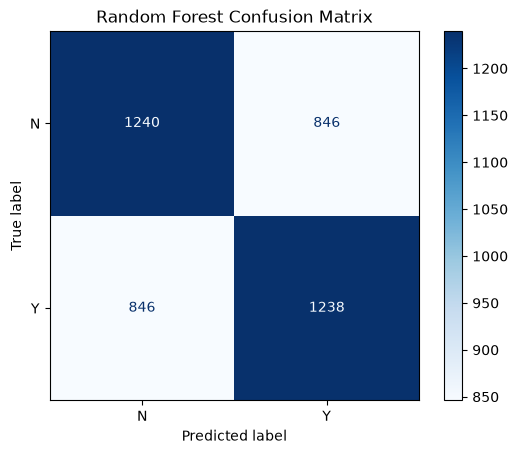

In [16]:
# Ensemble model: many decision trees vote for the final prediction
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=28,
    n_jobs=-1
)

random_forest.fit(X_train_tree, y_train)

random_forest_predictions = random_forest.predict(X_test_tree)
random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

print("Random Forest accuracy:", random_forest_accuracy)

print("\nRandom Forest classification report:")
print(
    classification_report(
        y_test,
        random_forest_predictions,
        labels=["N", "Y"]
    )
)

random_forest_matrix = confusion_matrix(
    y_test,
    random_forest_predictions,
    labels=["N", "Y"]
)

random_forest_display = ConfusionMatrixDisplay(
    confusion_matrix=random_forest_matrix,
    display_labels=["N", "Y"]
)

random_forest_display.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [17]:
# Final KNN predictions
knn_final_predictions = knn_standard.predict(X_test_standard)

# Final Decision Tree predictions
tree_final_predictions = final_tree.predict(X_test_tree)

# Compare the models
model_comparison = pd.DataFrame(
    {
        "Model": [
            "KNN + StandardScaler",
            "Decision Tree (max_depth=3)",
            "Random Forest"
        ],
        "Accuracy": [
            accuracy_score(y_test, knn_final_predictions),
            accuracy_score(y_test, tree_final_predictions),
            accuracy_score(y_test, random_forest_predictions)
        ],
        "Precision (Y)": [
            precision_score(y_test, knn_final_predictions, pos_label="Y"),
            precision_score(y_test, tree_final_predictions, pos_label="Y"),
            precision_score(y_test, random_forest_predictions, pos_label="Y")
        ],
        "Recall (Y)": [
            recall_score(y_test, knn_final_predictions, pos_label="Y"),
            recall_score(y_test, tree_final_predictions, pos_label="Y"),
            recall_score(y_test, random_forest_predictions, pos_label="Y")
        ],
        "F1-score (Y)": [
            f1_score(y_test, knn_final_predictions, pos_label="Y"),
            f1_score(y_test, tree_final_predictions, pos_label="Y"),
            f1_score(y_test, random_forest_predictions, pos_label="Y")
        ]
    }
)

model_comparison.round(3)

,Model,Accuracy,Precision (Y),Recall (Y),F1-score (Y)
0,KNN + StandardScaler,0.584,0.583,0.588,0.585
1,Decision Tree (max_depth=3),0.601,0.606,0.581,0.593
2,Random Forest,0.594,0.594,0.594,0.594


In [18]:
# Final columns used by the model
final_model_columns = (
    numeric_features
    + categorical_features
    + ["beat_teammate"]
)

# Missing values in final model columns
missing_values = f1v1[
    final_model_columns
].isna().sum()

print("Missing values in final model columns:")
print(missing_values[missing_values > 0])

# A driver must appear only once in each race
duplicate_driver_races = f1v1.duplicated(
    subset=["raceId", "driverId"]
).sum()

# Informational only:
# identical feature rows can be legitimate different races,
# so do NOT automatically remove them.
duplicate_model_rows = f1v1.duplicated(
    subset=final_model_columns
).sum()

print("\nDuplicate driver-race rows:", duplicate_driver_races)
print("Identical model rows:", duplicate_model_rows)

# Review duplicate driver-race records manually. Do not drop them automatically.
duplicate_driver_race_details = f1v1.loc[
    f1v1.duplicated(subset=["raceId", "driverId"], keep=False),
    [
        "resultId",
        "raceId",
        "year",
        "round",
        "name",
        "driverId",
        "forename",
        "surname",
        "constructorId",
        "name_constructor",
        "grid",
        "positionOrder",
        "statusId"
    ]
].sort_values(["raceId", "driverId", "resultId"])

if not duplicate_driver_race_details.empty:
    print("\nDuplicate details for manual review:")
    display(duplicate_driver_race_details)

Missing values in final model columns:
Series([], dtype: int64)

Duplicate driver-race rows: 1
Identical model rows: 0

Duplicate details for manual review:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
depth_grid = {
    "max_depth": [1, 2, 3, 4, 5, 6, 8, 10, 15, None]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=28
    ),
    param_grid=depth_grid,
    cv=5,
    scoring="accuracy",
    return_train_score=True
)

grid_search.fit(X_train_tree, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

Best parameters: {'max_depth': 3}
Best cross-validation accuracy: 0.6214628297362109


Final GridSearch Decision Tree test accuracy: 0.6014388489208633

Classification report:
              precision    recall  f1-score   support

           N       0.60      0.62      0.61      2086
           Y       0.61      0.58      0.59      2084

    accuracy                           0.60      4170
   macro avg       0.60      0.60      0.60      4170
weighted avg       0.60      0.60      0.60      4170



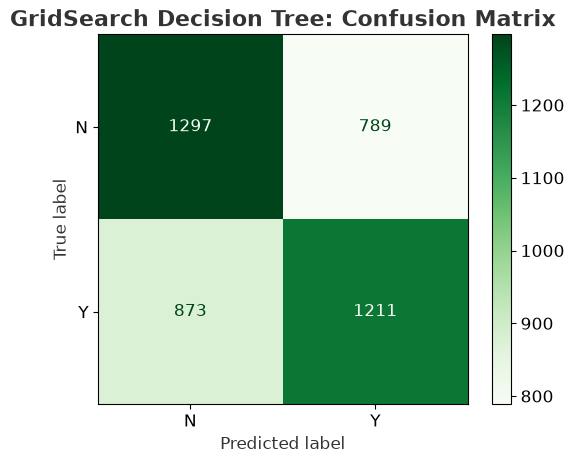

In [ ]:
best_tree = grid_search.best_estimator_

grid_predictions = best_tree.predict(X_test_tree)

grid_test_accuracy = accuracy_score(
    y_test,
    grid_predictions
)

print("Final GridSearch Decision Tree test accuracy:", grid_test_accuracy)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        grid_predictions,
        labels=["N", "Y"]
    )
)

grid_matrix = confusion_matrix(
    y_test,
    grid_predictions,
    labels=["N", "Y"]
)

grid_display = ConfusionMatrixDisplay(
    confusion_matrix=grid_matrix,
    display_labels=["N", "Y"]
)

grid_display.plot(cmap="Greens")
plt.title("GridSearch Decision Tree: Confusion Matrix")
plt.show()

In [20]:
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create separate models for this comparison
comparison_models = {
    "Baseline (most frequent class)": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        random_state=28
    ),
    "Decision Tree (default)": DecisionTreeClassifier(
        random_state=28
    ),
    "Decision Tree (max_depth=3)": DecisionTreeClassifier(
    max_depth=3,
    random_state=28
),
    "KNN + StandardScaler": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=28,
        n_jobs=-1
    ),
    "Bagging": BaggingClassifier(
        n_estimators=100,
        random_state=28,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=28
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=28
    )
}

comparison_rows = []

for model_name, comparison_model in comparison_models.items():

    # Distance-based and linear models use scaled numeric features
    if model_name in ["Logistic Regression", "KNN + StandardScaler"]:
        comparison_X_train = X_train_standard
        comparison_X_test = X_test_standard
    else:
        comparison_X_train = X_train_encoded
        comparison_X_test = X_test_encoded

    comparison_model.fit(comparison_X_train, y_train)

    comparison_train_predictions = comparison_model.predict(
        comparison_X_train
    )
    comparison_test_predictions = comparison_model.predict(
        comparison_X_test
    )

    comparison_rows.append({
        "Model": model_name,
        "Train accuracy": accuracy_score(
            y_train, comparison_train_predictions
        ),
        "Test accuracy": accuracy_score(
            y_test, comparison_test_predictions
        ),
        "Precision (Y)": precision_score(
            y_test, comparison_test_predictions,
            pos_label="Y", zero_division=0
        ),
        "Recall (Y)": recall_score(
            y_test, comparison_test_predictions,
            pos_label="Y", zero_division=0
        ),
        "F1-score (Y)": f1_score(
            y_test, comparison_test_predictions,
            pos_label="Y", zero_division=0
        )
    })

model_comparison = pd.DataFrame(comparison_rows)

model_comparison = model_comparison.sort_values(
    by="Test accuracy",
    ascending=False
)

model_comparison = model_comparison.reset_index(drop=True)

display(
    model_comparison.style.format({
        "Train accuracy": "{:.2%}",
        "Test accuracy": "{:.2%}",
        "Precision (Y)": "{:.2%}",
        "Recall (Y)": "{:.2%}",
        "F1-score (Y)": "{:.2%}"
    })
)

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [21]:
from IPython.display import display as show_table

show_table(
    model_comparison.style.format({
        "Train accuracy": "{:.2%}",
        "Test accuracy": "{:.2%}",
        "Precision (Y)": "{:.2%}",
        "Recall (Y)": "{:.2%}",
        "F1-score (Y)": "{:.2%}"
    })
)

,Model,Train accuracy,Test accuracy,Precision (Y),Recall (Y),F1-score (Y)
0,Gradient Boosting,64.77%,61.32%,61.57%,60.12%,60.84%
1,Decision Tree (max_depth=3),62.31%,60.14%,60.55%,58.11%,59.30%
2,Bagging,100.00%,59.71%,59.73%,59.50%,59.62%
3,Random Forest,100.00%,59.42%,59.40%,59.40%,59.40%
4,AdaBoost,61.64%,58.85%,58.03%,63.77%,60.77%
5,KNN + StandardScaler,72.54%,58.39%,58.31%,58.78%,58.54%
6,Decision Tree (default),100.00%,55.97%,55.79%,57.34%,56.55%
7,Logistic Regression,60.59%,55.61%,55.32%,58.16%,56.70%
8,Baseline (most frequent class),50.02%,50.02%,0.00%,0.00%,0.00%
